In [3]:
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from dotenv import load_dotenv
from langchain_core.messages import BaseMessage,HumanMessage
from typing import TypedDict,Annotated
from langgraph.checkpoint.memory import MemorySaver
from langchain_groq import ChatGroq
load_dotenv()

True

In [4]:
llm = ChatGroq(model='openai/gpt-oss-120b')


In [5]:
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [6]:
def chat_node(state:ChatState):
    messages = state['messages']
    response = llm.invoke(messages)
    return {'messages':[response]}

In [7]:
checkpoint = MemorySaver()
graph = StateGraph(ChatState)

graph.add_node('chat_node',chat_node)

graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

workflow = graph.compile(checkpointer=checkpoint)

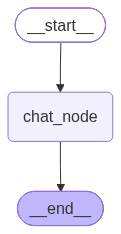

In [8]:
workflow

In [11]:
initial_state={
    'messages':[HumanMessage(content="What is object oriented programming?")]
}

response = workflow.invoke(initial_state)

In [12]:
response

{'messages': [HumanMessage(content='What is object oriented programming?', additional_kwargs={}, response_metadata={}, id='f1a94f31-fb1c-4a88-b909-fcefc5c2e86c'),
  AIMessage(content='**Object‑Oriented Programming (OOP)** is a programming paradigm that organizes software around **objects**—self‑contained units that bundle both data (attributes) and behavior (methods). Instead of writing a linear list of instructions, you model the problem domain as a collection of interacting objects that mimic real‑world entities or abstract concepts.\n\n---\n\n## Core Concepts\n\n| Concept | What it means | Typical keyword (e.g., in Java/C#/Python) |\n|---------|---------------|-------------------------------------------|\n| **Class** | A blueprint or template for objects. It defines the attributes (state) and methods (behaviors) that its instances will have. | `class` |\n| **Object / Instance** | A concrete realization of a class. Each object has its own copy of the class’s attributes. | `new MyClas

In [14]:
response['messages'][1].content

'**Object‑Oriented Programming (OOP)** is a programming paradigm that organizes software around **objects**—self‑contained units that bundle both data (attributes) and behavior (methods). Instead of writing a linear list of instructions, you model the problem domain as a collection of interacting objects that mimic real‑world entities or abstract concepts.\n\n---\n\n## Core Concepts\n\n| Concept | What it means | Typical keyword (e.g., in Java/C#/Python) |\n|---------|---------------|-------------------------------------------|\n| **Class** | A blueprint or template for objects. It defines the attributes (state) and methods (behaviors) that its instances will have. | `class` |\n| **Object / Instance** | A concrete realization of a class. Each object has its own copy of the class’s attributes. | `new MyClass()` (Java), `MyClass()` (Python) |\n| **Encapsulation** | Hides an object’s internal state and forces interaction through well‑defined interfaces (methods). Helps protect data integr

In [ ]:
thread_id = "1"
config = {'configurable':{"thread_id":thread_id}}

In [10]:
workflow.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='32f24659-4e08-4ef3-97b9-96a5dad73ec4'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi". Need to respond. Should be friendly. No disallowed content. Just greet.'}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 72, 'total_tokens': 113, 'completion_time': 0.087461733, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.002771273, 'prompt_tokens_details': None, 'queue_time': 0.350055414, 'total_time': 0.090233006}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_fe269835c7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a089a8-b068-7281-be28-6d4b266cd126-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 41, 'total_tokens': 113, 'output_token

In [ ]:

while True:
    user_message = input('Type Here: ')
    print('User :',user_message)
    
    if user_message.strip().lower() in ['exit','quit','bye']:
        break
    response = workflow.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
    print('AI:',response['messages'][-1].content)

User : Hi
AI: Hello! How can I help you today?
User : My name is random_user
AI: Nice to meet you, random_user! How can I assist you today?
User : explain python in 10 words
AI: High-level, interpreted language for readable, versatile, object-oriented programming and development.
User : what is my name
AI: You told me your name is **random_user**.
User : who is adolf hitler explain in 10 words
AI: Austrian dictator, WWII leader, perpetrated Holocaust, caused massive devastation.
User : who won election of india in 2023
AI: India did **not** hold a national (Lok Sabha) general election in 2023.  
Instead, several **state assembly elections** took place, and the outcomes were:

| State (2023) | Winning Party / Alliance | Chief Minister (post‑election) |
|--------------|--------------------------|--------------------------------|
| **Karnataka** (May 2023) | **Indian National Congress (INC)** (led a coalition with JD (S) and others) | **K. S. Ashwath Rao** (INC) |
| **Madhya Pradesh** (No